<h1><b>Explainable Artificial Intelligence Framework for Medical Disease Prediction and Diagnosis

<h2><b>Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.metrics import (
    mean_squared_error, r2_score,
    accuracy_score, confusion_matrix,
    classification_report, roc_curve, auc
)

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

In [3]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=ba03f5114c0ff76d199348b33dbb49019b89b3205ce60afd68471894b943d35a
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [4]:
!pip install shap lime

In [5]:
import shap
import lime
import lime.lime_tabular

<h2><b>Load Dataset

In [6]:
import pandas as pd

# Load dataset
df = pd.read_csv("/content/heart.csv")

<h2><b>Data Exploration (EDA)

In [7]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [9]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [10]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


<h3><b>Class Distribution (Target)

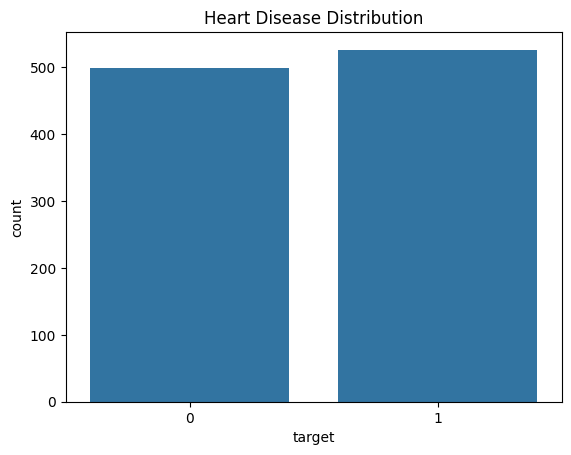

In [11]:
sns.countplot(x='target', data=df)
plt.title("Heart Disease Distribution")
plt.show()

<h3><b>Age Distribution

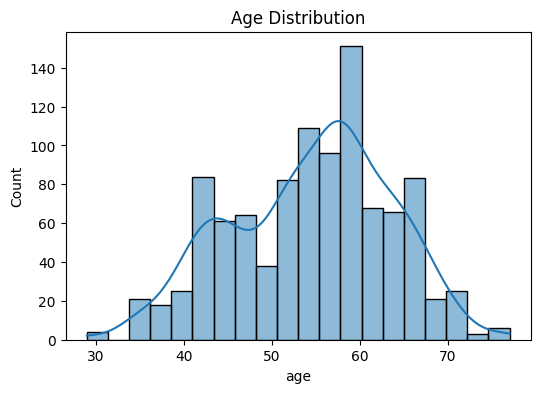

In [12]:
plt.figure(figsize=(6,4))
sns.histplot(df['age'], bins=20, kde=True)
plt.title("Age Distribution")
plt.show()

<h3><b>Gender vs Disease

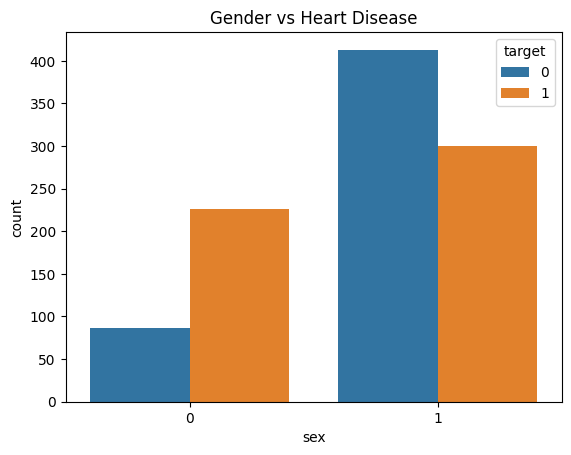

In [13]:
sns.countplot(x='sex', hue='target', data=df)
plt.title("Gender vs Heart Disease")
plt.show()

<h3><b>Chest Pain Type

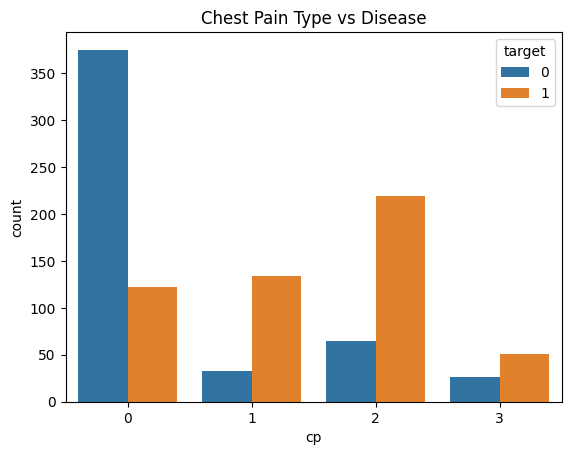

In [14]:
sns.countplot(x='cp', hue='target', data=df)
plt.title("Chest Pain Type vs Disease")
plt.show()

<h3><b>Correlation Heatmap

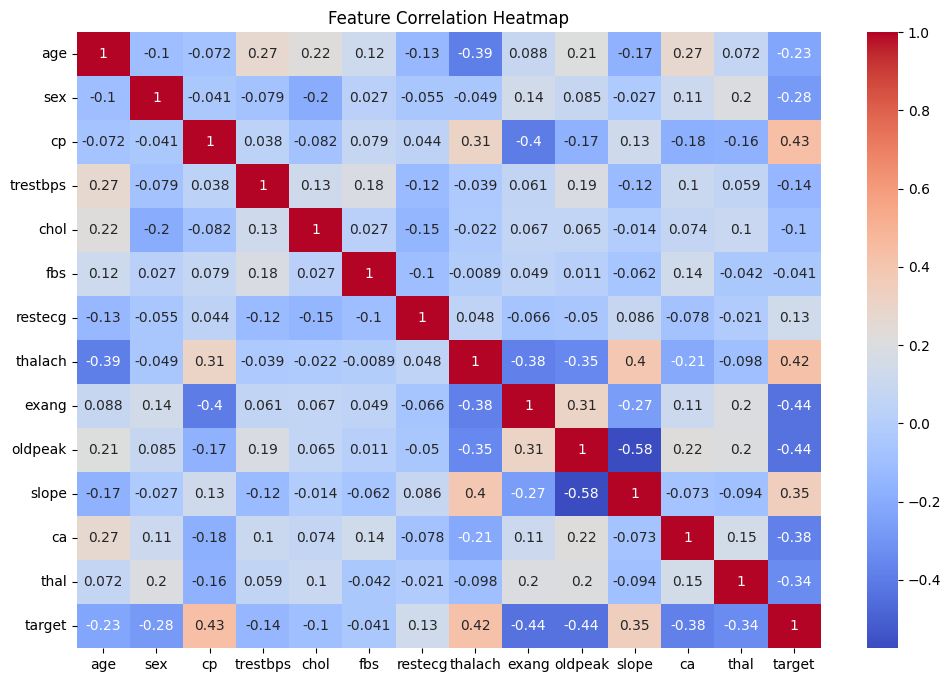

In [15]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

<h3><b>Cholesterol Distribution

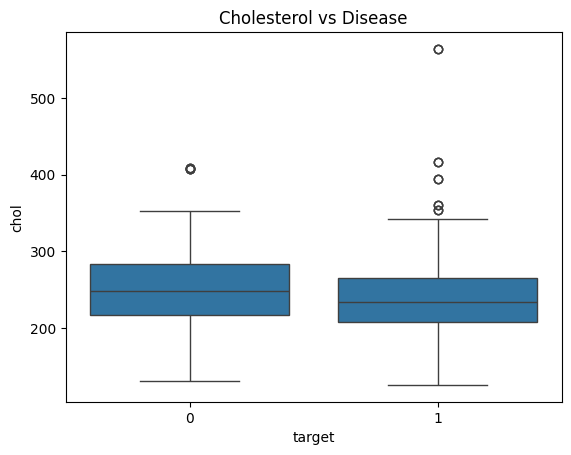

In [16]:
sns.boxplot(x='target', y='chol', data=df)
plt.title("Cholesterol vs Disease")
plt.show()

<h3><b>Max Heart Rate

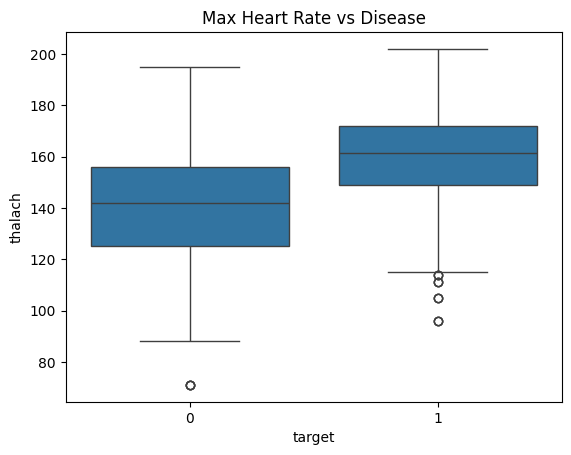

In [17]:
sns.boxplot(x='target', y='thalach', data=df)
plt.title("Max Heart Rate vs Disease")
plt.show()

<h3><b>Resting Blood Pressure

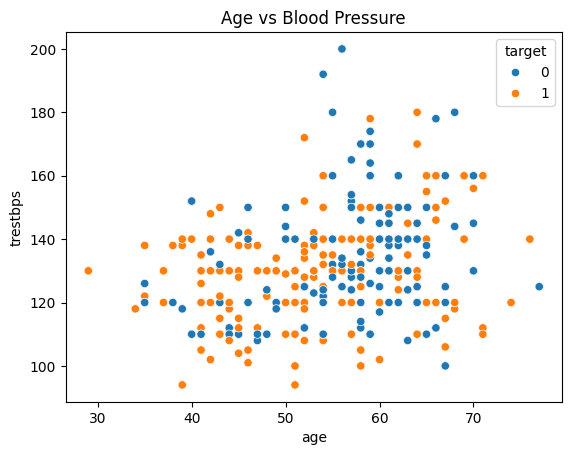

In [18]:
sns.scatterplot(x='age', y='trestbps', hue='target', data=df)
plt.title("Age vs Blood Pressure")
plt.show()

<h3><b>Pairplot (Feature Relationship)

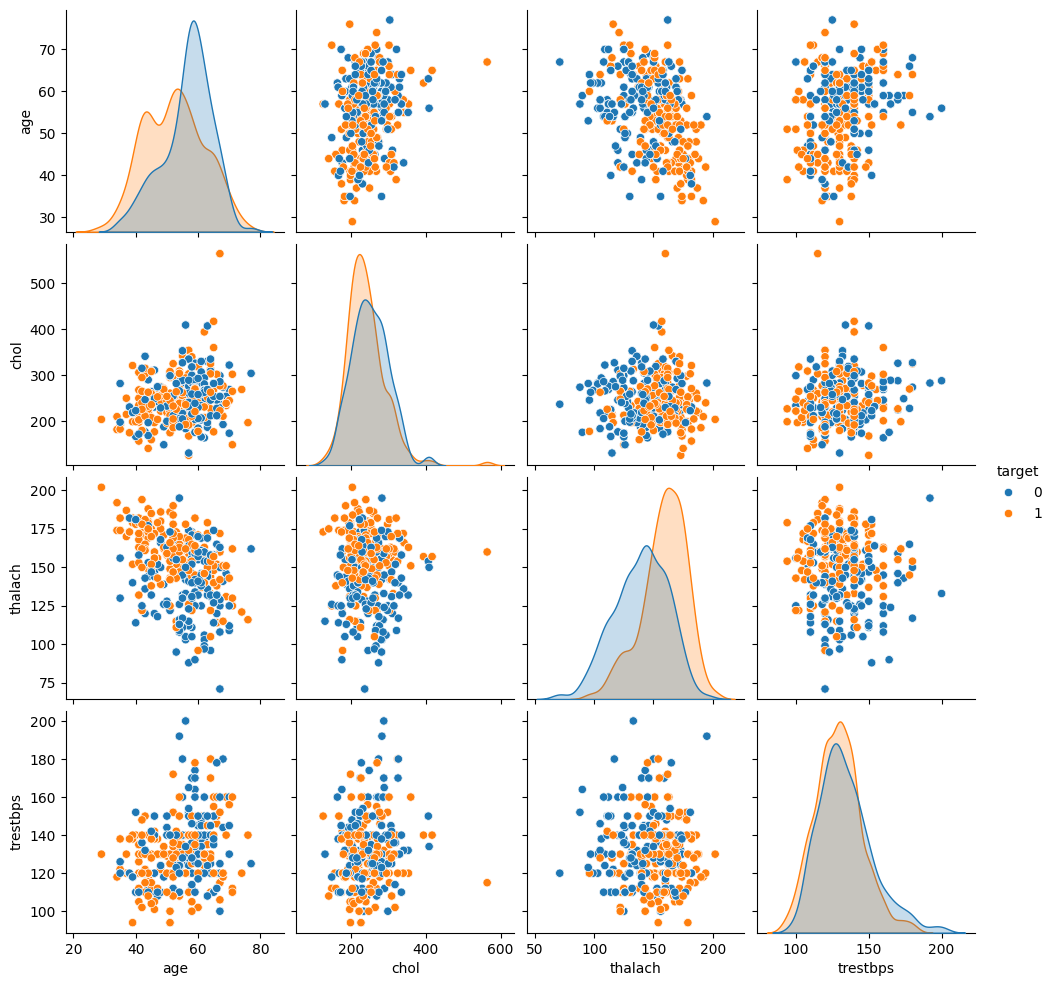

In [19]:
sns.pairplot(df[['age','chol','thalach','trestbps','target']], hue='target')
plt.show()

<h2><b>Data Preprocessing

In [20]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [21]:
X = df.drop('target', axis=1)
y = df['target']

In [22]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

<h2><b>Feature Selection (Correlation-Based)

In [24]:
corr = df.corr()['target'].sort_values(ascending=False)
print(corr)

target      1.000000
cp          0.434854
thalach     0.422895
slope       0.345512
restecg     0.134468
fbs        -0.041164
chol       -0.099966
trestbps   -0.138772
age        -0.229324
sex        -0.279501
thal       -0.337838
ca         -0.382085
exang      -0.438029
oldpeak    -0.438441
Name: target, dtype: float64


<h2><b>Model Training

<h3><b>Decision Tree

In [25]:
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

<h3><b>SVM

In [26]:
svm_model = SVC(kernel='rbf')
svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

<h3><b>Neural Network

In [27]:
nn_model = MLPClassifier(hidden_layer_sizes=(64,32), max_iter=500)
nn_model.fit(X_train, y_train)

nn_pred = nn_model.predict(X_test)

<h2><b>Model Evaluation Function

In [28]:
def evaluate_model(name, y_true, y_pred):
    print("\n", name)
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))

<h2><b>CLASSIFICATION REPORT (ALL MODELS)

In [29]:
from sklearn.metrics import classification_report

print("=== Decision Tree ===")
print(classification_report(y_test, dt_pred))

print("=== SVM ===")
print(classification_report(y_test, svm_pred))

print("=== Neural Network ===")
print(classification_report(y_test, nn_pred))

=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

=== SVM ===
              precision    recall  f1-score   support

           0       0.93      0.83      0.88       102
           1       0.85      0.94      0.89       103

    accuracy                           0.89       205
   macro avg       0.89      0.89      0.89       205
weighted avg       0.89      0.89      0.89       205

=== Neural Network ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg     

<h2><b>Confusion Matrix all Models

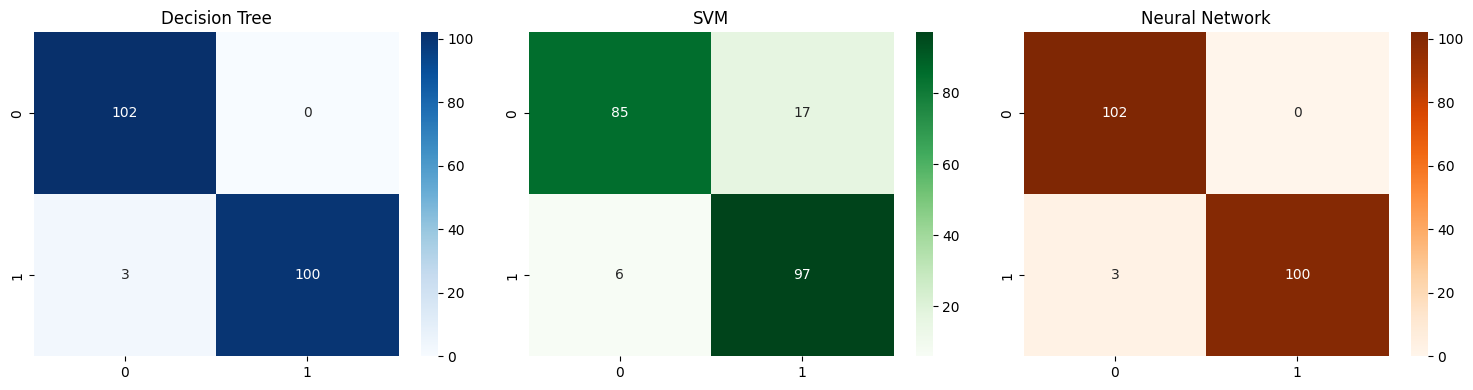

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

sns.heatmap(confusion_matrix(y_test, dt_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("Decision Tree")

sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("SVM")

sns.heatmap(confusion_matrix(y_test, nn_pred), annot=True, fmt='d', cmap='Oranges', ax=axes[2])
axes[2].set_title("Neural Network")

plt.tight_layout()
plt.show()

<h2><b>ROC CURVE + AUC (ALL MODELS)

In [31]:
dt_prob = dt_model.predict_proba(X_test)[:,1]
svm_prob = svm_model.decision_function(X_test)
nn_prob = nn_model.predict_proba(X_test)[:,1]

In [32]:
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_prob)
roc_auc_dt = auc(fpr_dt, tpr_dt)

fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_prob)
roc_auc_svm = auc(fpr_svm, tpr_svm)

fpr_nn, tpr_nn, _ = roc_curve(y_test, nn_prob)
roc_auc_nn = auc(fpr_nn, tpr_nn)

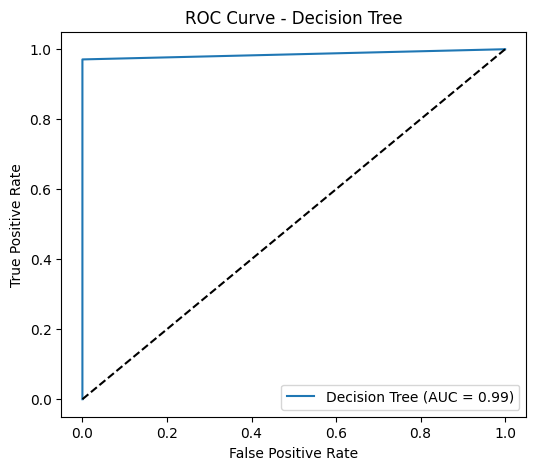

In [41]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_prob)
roc_auc_dt = auc(fpr_dt, tpr_dt)

plt.figure(figsize=(6,5))
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {roc_auc_dt:.2f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.show()

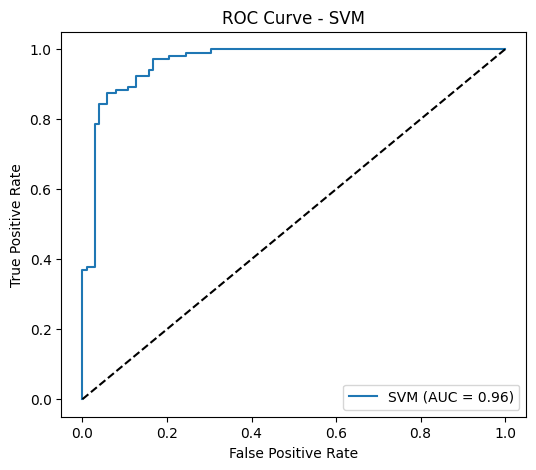

In [42]:
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_prob)
roc_auc_svm = auc(fpr_svm, tpr_svm)

plt.figure(figsize=(6,5))
plt.plot(fpr_svm, tpr_svm, label=f"SVM (AUC = {roc_auc_svm:.2f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM")
plt.legend()
plt.show()

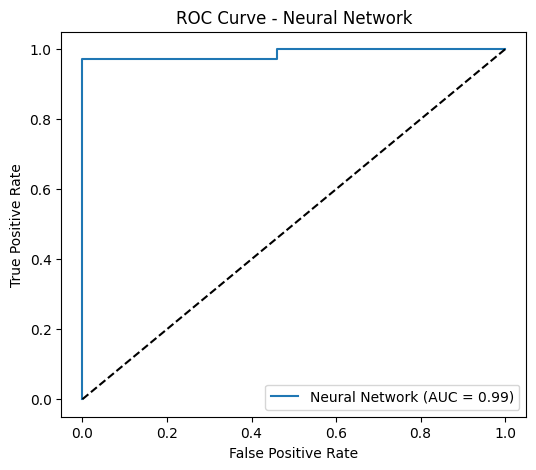

In [43]:
fpr_nn, tpr_nn, _ = roc_curve(y_test, nn_prob)
roc_auc_nn = auc(fpr_nn, tpr_nn)

plt.figure(figsize=(6,5))
plt.plot(fpr_nn, tpr_nn, label=f"Neural Network (AUC = {roc_auc_nn:.2f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Neural Network")
plt.legend()
plt.show()

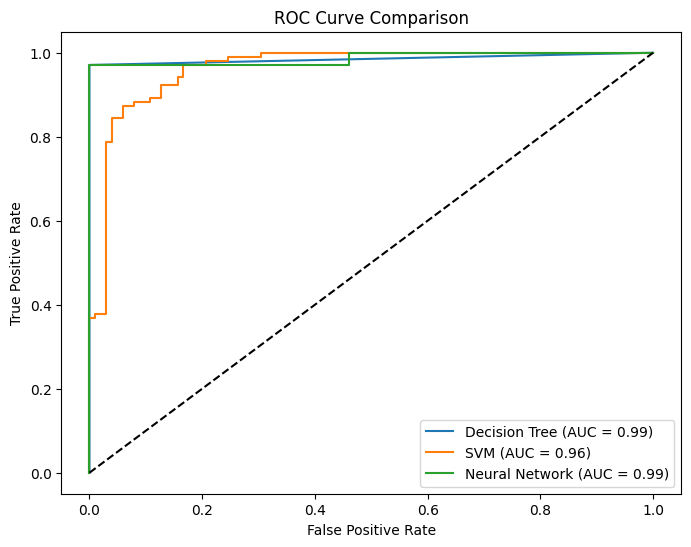

In [33]:
plt.figure(figsize=(8,6))

plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {roc_auc_dt:.2f})')
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {roc_auc_svm:.2f})')
plt.plot(fpr_nn, tpr_nn, label=f'Neural Network (AUC = {roc_auc_nn:.2f})')

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

<h2><b>MODEL COMPARISON GRAPH (ACCURACY)

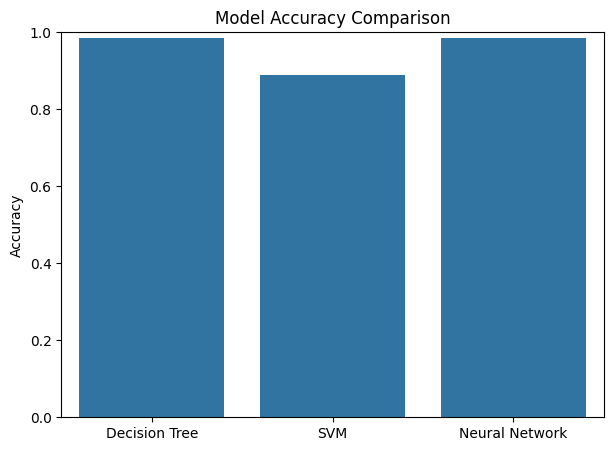

In [34]:
models = ['Decision Tree', 'SVM', 'Neural Network']

accuracy = [
    accuracy_score(y_test, dt_pred),
    accuracy_score(y_test, svm_pred),
    accuracy_score(y_test, nn_pred)
]

plt.figure(figsize=(7,5))
sns.barplot(x=models, y=accuracy)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0,1)
plt.show()

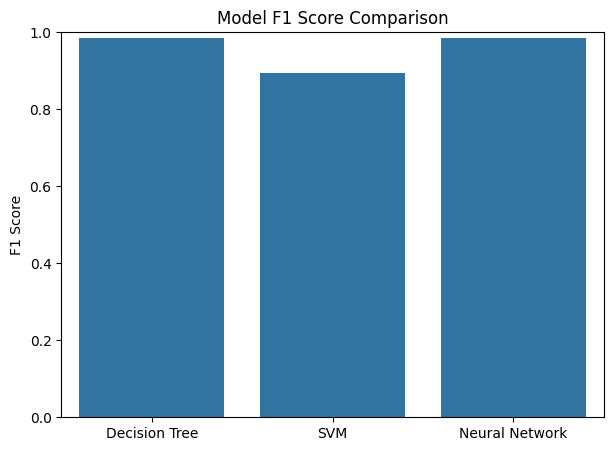

In [35]:
f1_scores = [
    f1_score(y_test, dt_pred),
    f1_score(y_test, svm_pred),
    f1_score(y_test, nn_pred)
]

plt.figure(figsize=(7,5))
sns.barplot(x=models, y=f1_scores)
plt.title("Model F1 Score Comparison")
plt.ylabel("F1 Score")
plt.ylim(0,1)
plt.show()

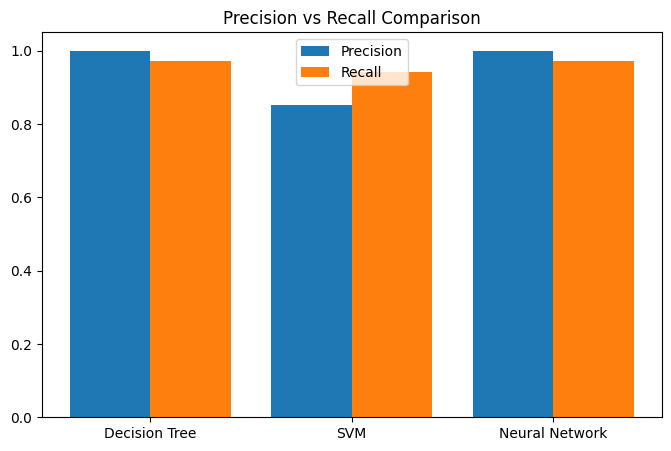

In [36]:
precision_scores = [
    precision_score(y_test, dt_pred),
    precision_score(y_test, svm_pred),
    precision_score(y_test, nn_pred)
]

recall_scores = [
    recall_score(y_test, dt_pred),
    recall_score(y_test, svm_pred),
    recall_score(y_test, nn_pred)
]

x = np.arange(len(models))

plt.figure(figsize=(8,5))
plt.bar(x - 0.2, precision_scores, 0.4, label='Precision')
plt.bar(x + 0.2, recall_scores, 0.4, label='Recall')

plt.xticks(x, models)
plt.title("Precision vs Recall Comparison")
plt.legend()
plt.show()

In [37]:
results = {
    "Decision Tree": accuracy_score(y_test, dt_pred),
    "SVM": accuracy_score(y_test, svm_pred),
    "Neural Network": accuracy_score(y_test, nn_pred)
}

best_model = max(results, key=results.get)

print("Model Accuracies:", results)
print("Best Model:", best_model)

Model Accuracies: {'Decision Tree': 0.9853658536585366, 'SVM': 0.8878048780487805, 'Neural Network': 0.9853658536585366}
Best Model: Decision Tree


<h1><b>Explainable AI (XAI)

<h2><b>SHAP (Tree-based explanation)

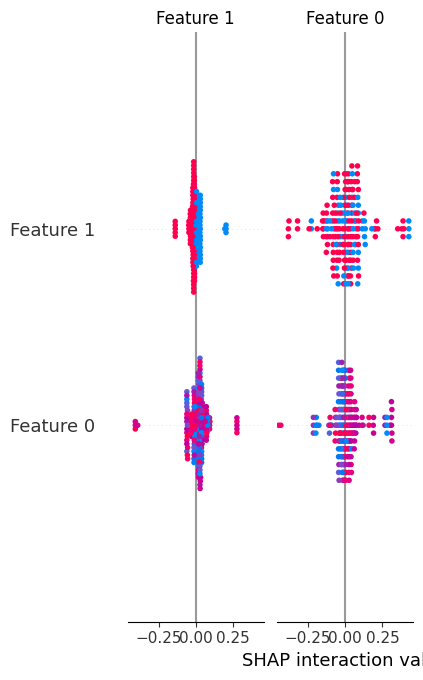

In [38]:
explainer = shap.Explainer(dt_model, X_train)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)

<h2><b>LIME Explanation

In [39]:
explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train,
    feature_names=X.columns,
    class_names=['No Disease', 'Disease'],
    mode='classification'
)

i = 0
exp = explainer.explain_instance(X_test[i], dt_model.predict_proba)
exp.show_in_notebook()

<h2><b>Prediction on New Data

In [40]:
new_patient = np.array([[63, 1, 3, 145, 233, 1, 0, 150, 0, 2.3, 0, 0, 1]])

new_patient_scaled = scaler.transform(new_patient)

prediction = dt_model.predict(new_patient_scaled)

if prediction[0] == 1:
    print("Heart Disease Detected")
else:
    print("No Heart Disease")

Heart Disease Detected


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
